# CSC-40080 Summative: Telco Customer Churn


## Cell 1: Imports and loading the data


In [1]:
import pandas as pd, numpy as np, sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)
from google.colab import files

uploaded = files.upload()
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Cell 2: SQL for access and aggregation


In [2]:
conn = sqlite3.connect(":memory:")
df.to_sql("customers", conn, index=False, if_exists="replace")

query = """
SELECT Contract,
       COUNT(*) AS customers,
       ROUND(AVG(CASE WHEN Churn = 'Yes' THEN 1.0 ELSE 0 END) * 100, 1) AS churn_pct,
       ROUND(AVG(MonthlyCharges), 2) AS avg_monthly
FROM customers
GROUP BY Contract
ORDER BY churn_pct DESC;
"""
pd.read_sql(query, conn)

,Contract,customers,churn_pct,avg_monthly
0,Month-to-month,3875,42.7,66.40
1,One year,1473,11.3,65.05
2,Two year,1695,2.8,60.77


## Cell 3: Cleaning


In [3]:
print(df.isna().sum().sum(), "missing before conversion")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")
print(df["TotalCharges"].isna().sum(), "blank TotalCharges")
print(df[df["TotalCharges"].isna()][["tenure"]].describe())

df = df.dropna(subset=["TotalCharges"])
df = df.drop(columns="customerID")
print("duplicates:", df.duplicated().sum())

df["Churn"] = (df["Churn"] == "Yes").astype(int)
print(df["Churn"].value_counts(normalize=True))

0 missing before conversion
11 blank TotalCharges
       tenure
count    11.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
duplicates: 22
Churn
0    0.734215
1    0.265785
Name: proportion, dtype: float64


## Cell 4: Exploring the data

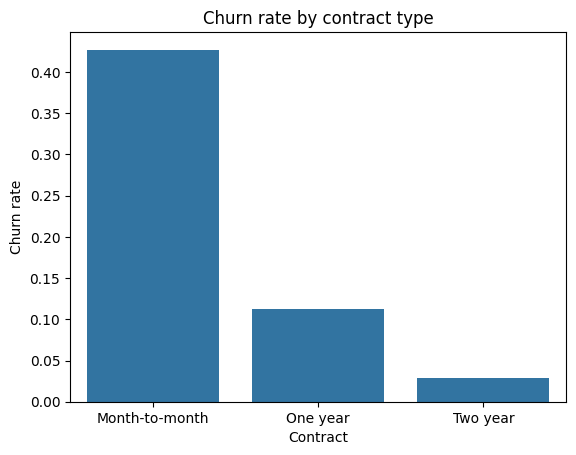

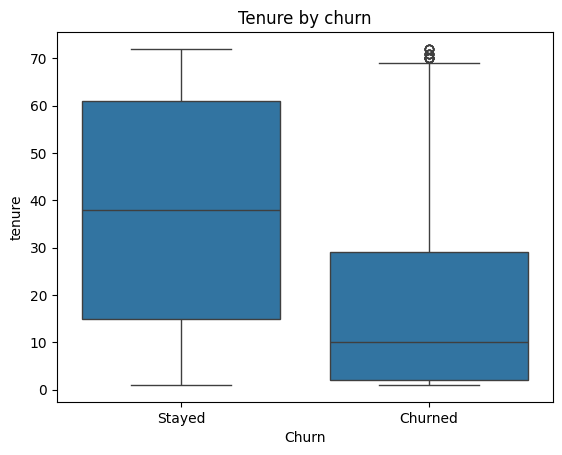

,tenure,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000,7032.000000
mean,32.421786,64.798208,2283.300441
std,24.545260,30.085974,2266.771362
min,1.000000,18.250000,18.800000
25%,9.000000,35.587500,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.862500,3794.737500
max,72.000000,118.750000,8684.800000


In [4]:
sns.barplot(data=df, x="Contract", y="Churn", errorbar=None)
plt.ylabel("Churn rate"); plt.title("Churn rate by contract type")
plt.show()

sns.boxplot(data=df, x="Churn", y="tenure")
plt.xticks([0, 1], ["Stayed", "Churned"]); plt.title("Tenure by churn")
plt.show()

df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

## Cell 5: Statistical tests (method 1)


In [5]:
ct = pd.crosstab(df["Contract"], df["Churn"])
chi2, p, dof, expected = stats.chi2_contingency(ct)
print(ct)
print(f"chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2e}")

n = ct.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
print(f"Cramer's V = {cramers_v:.2f}")
print("Smallest expected count:", expected.min().round(1), "(should be 5 or more)")

a = df[df["Churn"] == 1]["MonthlyCharges"]
b = df[df["Churn"] == 0]["MonthlyCharges"]
t, p_t = stats.ttest_ind(a, b, equal_var=False)
print(f"t = {t:.2f}, p = {p_t:.2e}")
print("Mean monthly charge: churned", round(a.mean(), 2), "vs stayed", round(b.mean(), 2))

Churn              0     1
Contract                  
Month-to-month  2220  1655
One year        1306   166
Two year        1637    48
chi2 = 1179.5, dof = 2, p = 7.33e-257
Cramer's V = 0.41
Smallest expected count: 391.2 (should be 5 or more)
t = 18.34, p = 2.66e-72
Mean monthly charge: churned 74.44 vs stayed 61.31


## Cell 6: Encoding, split and scaling


In [6]:
X = pd.get_dummies(df.drop(columns="Churn"), drop_first=True)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()
X_train = X_train.copy(); X_test = X_test.copy()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])
print(X_train.shape, X_test.shape)

(5625, 30) (1407, 30)


## Cell 7: Models and benchmark (method 2 plus benchmark)


Benchmark (majority class)
              precision    recall  f1-score   support

      Stayed       0.73      1.00      0.85      1033
     Churned       0.00      0.00      0.00       374

    accuracy                           0.73      1407
   macro avg       0.37      0.50      0.42      1407
weighted avg       0.54      0.73      0.62      1407



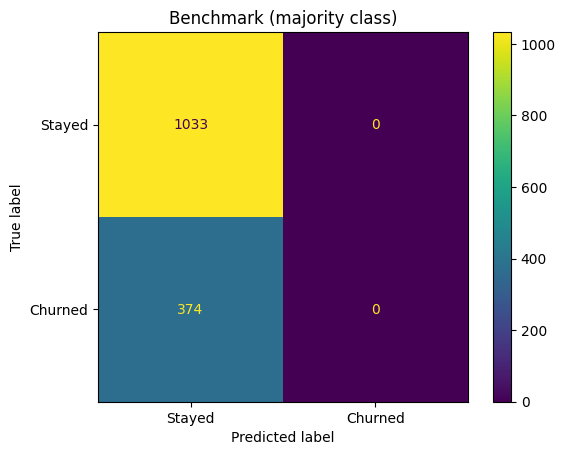

Logistic regression
              precision    recall  f1-score   support

      Stayed       0.90      0.70      0.79      1033
     Churned       0.49      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



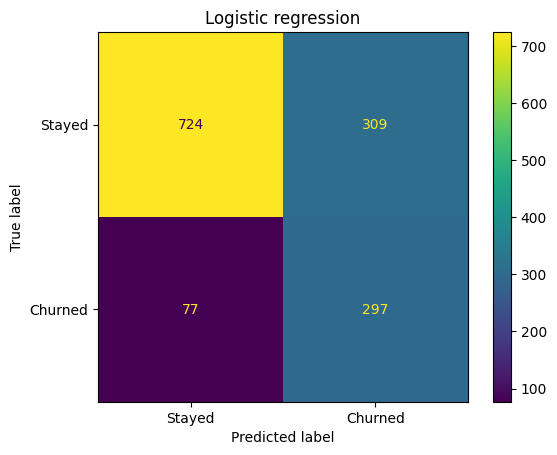

Decision tree
              precision    recall  f1-score   support

      Stayed       0.90      0.68      0.77      1033
     Churned       0.47      0.78      0.59       374

    accuracy                           0.71      1407
   macro avg       0.68      0.73      0.68      1407
weighted avg       0.78      0.71      0.72      1407



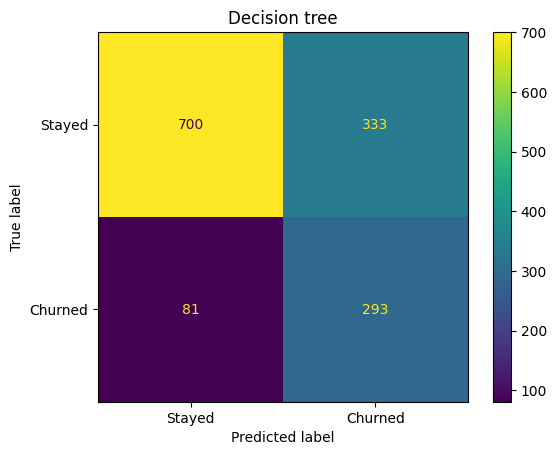

In [7]:
models = {
    "Benchmark (majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced",
                                            random_state=42),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print("=" * 50); print(name)
    print(classification_report(y_test, pred, target_names=["Stayed", "Churned"], zero_division=0))
    results[name] = pred

    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Stayed", "Churned"]).plot()
    plt.title(name); plt.show()

## Cell 8: Feature importance and odds ratio (for interpretation)


Lowest odds ratios (linked to staying):
Contract_Two year     0.232940
tenure                0.285637
Contract_One year     0.454536
MonthlyCharges        0.615115
PhoneService_Yes      0.688603
OnlineSecurity_Yes    0.705271
TechSupport_Yes       0.735209
Dependents_Yes        0.795299
dtype: float64

Highest odds ratios (linked to churn):
SeniorCitizen                     1.227579
PaperlessBilling_Yes              1.291975
MultipleLines_Yes                 1.400214
StreamingMovies_Yes               1.450130
StreamingTV_Yes                   1.472513
PaymentMethod_Electronic check    1.508338
TotalCharges                      1.834176
InternetService_Fiber optic       3.110593
dtype: float64


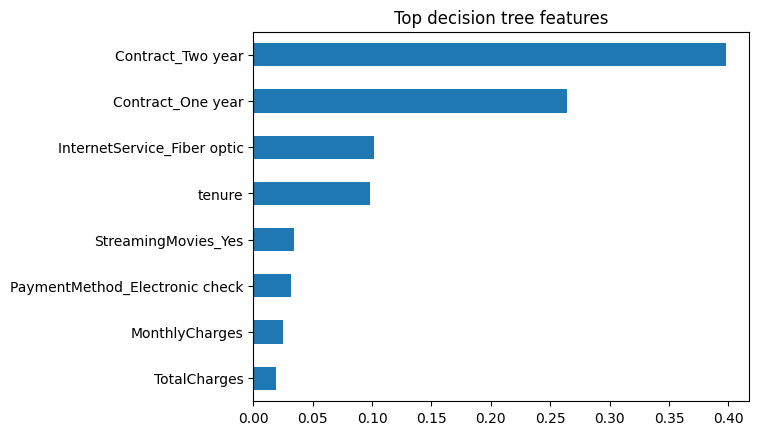

ROC AUC logistic regression: 0.835
ROC AUC decision tree: 0.818


In [8]:
lr = models["Logistic regression"]
odds = pd.Series(np.exp(lr.coef_[0]), index=X_train.columns).sort_values()
print("Lowest odds ratios (linked to staying):"); print(odds.head(8))
print("\nHighest odds ratios (linked to churn):"); print(odds.tail(8))

dt = models["Decision tree"]
imp = pd.Series(dt.feature_importances_, index=X_train.columns)
imp.sort_values(ascending=False).head(8).plot(kind="barh")
plt.title("Top decision tree features"); plt.gca().invert_yaxis(); plt.show()

print("ROC AUC logistic regression:", round(roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1]), 3))
print("ROC AUC decision tree:", round(roc_auc_score(y_test, dt.predict_proba(X_test)[:, 1]), 3))

## Cell 9: Save the cleaned dataset for your appendix

In [9]:
clean = pd.concat([X, y], axis=1)
clean.to_csv("telco_churn_cleaned.csv", index=False)
files.download("telco_churn_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>